# 01 · Explore input datasets (C1 output)

C2 receives cleaned features from **C1**. Until C1 is integrated we use the *dummy C1 output* built by `scripts/build_dummy_data.py`.

Change `DATASET` and re-run all cells.

In [1]:
import json, ast, glob
from pathlib import Path
import pandas as pd
import matplotlib.pyplot as plt

from c2_automl.config import OUTPUT_DIR
from c2_automl.io.dummy_c1 import load_c1_output, load_split

# Validated light palette (same colours as the dashboard)
FAMILY_COLORS = {"random_forest": "#2a78d6", "xgboost": "#eb6834", "lightgbm": "#1baf7a",
                 "catboost": "#eda100", "logistic_regression": "#e87ba4", "ridge": "#008300"}
ROUND_COLORS = {1: "#86b6ef", 2: "#3987e5", 3: "#184f95", 4: "#0d366b"}
plt.rcParams.update({"figure.facecolor": "#fcfcfb", "axes.facecolor": "#fcfcfb",
                     "axes.edgecolor": "#c3c2b7", "axes.grid": True, "grid.color": "#e1e0d9",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.labelcolor": "#52514e", "xtick.color": "#898781", "ytick.color": "#898781",
                     "font.size": 10, "lines.linewidth": 2})

Matplotlib is building the font cache; this may take a moment.


In [2]:
DATASET = "adult_imbalanced"   # adult | diabetes | adult_imbalanced | your upload

c1 = load_c1_output(DATASET)
X, y = load_split(c1, "train")
print(f"{DATASET}: {X.shape[0]} train rows, {X.shape[1]} features, task={c1.task_type.value}, "
      f"positive class={c1.positive_class!r}")
X.head()

adult_imbalanced: 30643 train rows, 14 features, task=binary, positive class='>50K'


,age,workclass,fnlwgt,education,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country
42579,24,1,103277,9,13,4,9,3,4,0,0,0,50,38
4821,55,8,227243,11,9,6,14,4,4,0,0,0,35,32
7890,33,3,269605,11,9,4,3,1,4,1,0,0,32,38
3721,62,3,235997,2,8,6,0,4,4,0,0,0,37,25
37466,37,3,360743,15,10,2,2,0,2,1,0,0,40,38


## Class balance
A strongly imbalanced target is what Agent 1 diagnoses as `class_imbalance`.

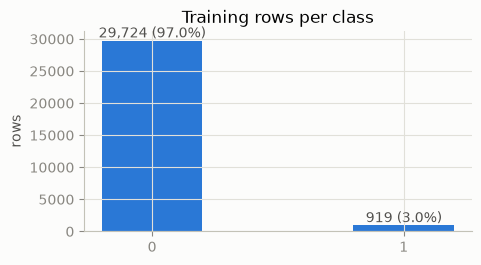

In [3]:
counts = y.value_counts().sort_index()
fig, ax = plt.subplots(figsize=(5, 2.6))
ax.bar([str(i) for i in counts.index], counts.values, width=0.4, color="#2a78d6")
for i, v in enumerate(counts.values):
    ax.text(i, v, f"{v:,} ({v / counts.sum():.1%})", ha="center", va="bottom", color="#52514e")
ax.set_title("Training rows per class"); ax.set_ylabel("rows"); plt.show()

## Feature Quality Score (FQS)
In the dummy C1 output the FQS is mutual information scaled to 0–1. The real C1 will provide a richer score.

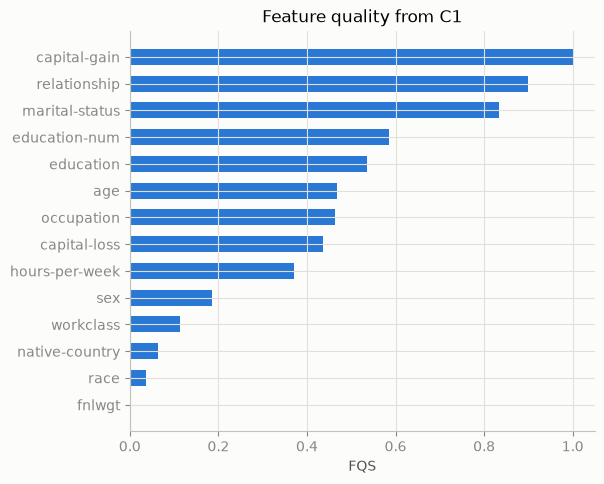

In [4]:
fqs = pd.Series(c1.fqs).sort_values()
fig, ax = plt.subplots(figsize=(6, 0.3 * len(fqs) + 1))
ax.barh(fqs.index, fqs.values, height=0.6, color="#2a78d6")
ax.set_xlim(0, 1.05); ax.set_xlabel("FQS")
ax.set_title("Feature quality from C1"); plt.show()

## Top features by class

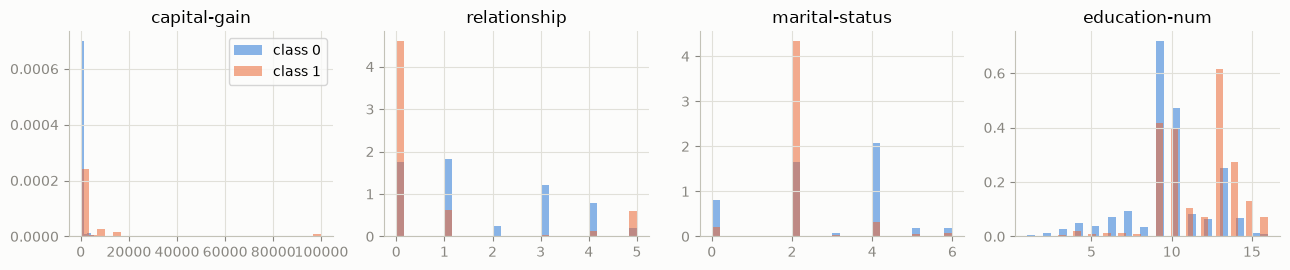

In [5]:
top = fqs.sort_values(ascending=False).index[:4]
fig, axes = plt.subplots(1, len(top), figsize=(13, 2.8))
for ax, col in zip(axes, top):
    for cls, color in [(0, "#2a78d6"), (1, "#eb6834")]:
        ax.hist(X.loc[y == cls, col], bins=30, alpha=0.55, color=color, density=True, label=f"class {cls}")
    ax.set_title(col)
axes[0].legend(); plt.tight_layout(); plt.show()